In [1]:
from pathlib import Path
import sys

# Find the repository when this notebook is opened from root or case_study.
_repo_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                   if (p / 'src' / 'paths.py').is_file()), None)
if _repo_root is None:
    raise RuntimeError('Run this notebook from within the repository directory.')
if str(_repo_root) not in sys.path:
    sys.path.insert(0, str(_repo_root))

# mean-variance portfolio allocation
import pandas as pd
import numpy as np
import math
import cvxpy as cp

import time

from torch.autograd.functional import jacobian
from torch.autograd.functional import hessian
import torch
from scipy.stats import chi2, norm, multivariate_normal
from sklearn.neighbors import KernelDensity

from src.portfolio_model import mv_portfolio

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib


[[-5.712 -5.733 -5.725 -5.716 -5.707 -5.699 -5.688 -5.68  -5.67  -5.661]
 [-5.87  -5.845 -5.825 -5.81  -5.795 -5.78  -5.766 -5.754 -5.74  -5.73 ]
 [-5.704 -5.733 -5.717 -5.702 -5.69  -5.68  -5.67  -5.66  -5.65  -5.64 ]
 [-5.707 -5.701 -5.69  -5.675 -5.66  -5.645 -5.635 -5.62  -5.605 -5.59 ]]


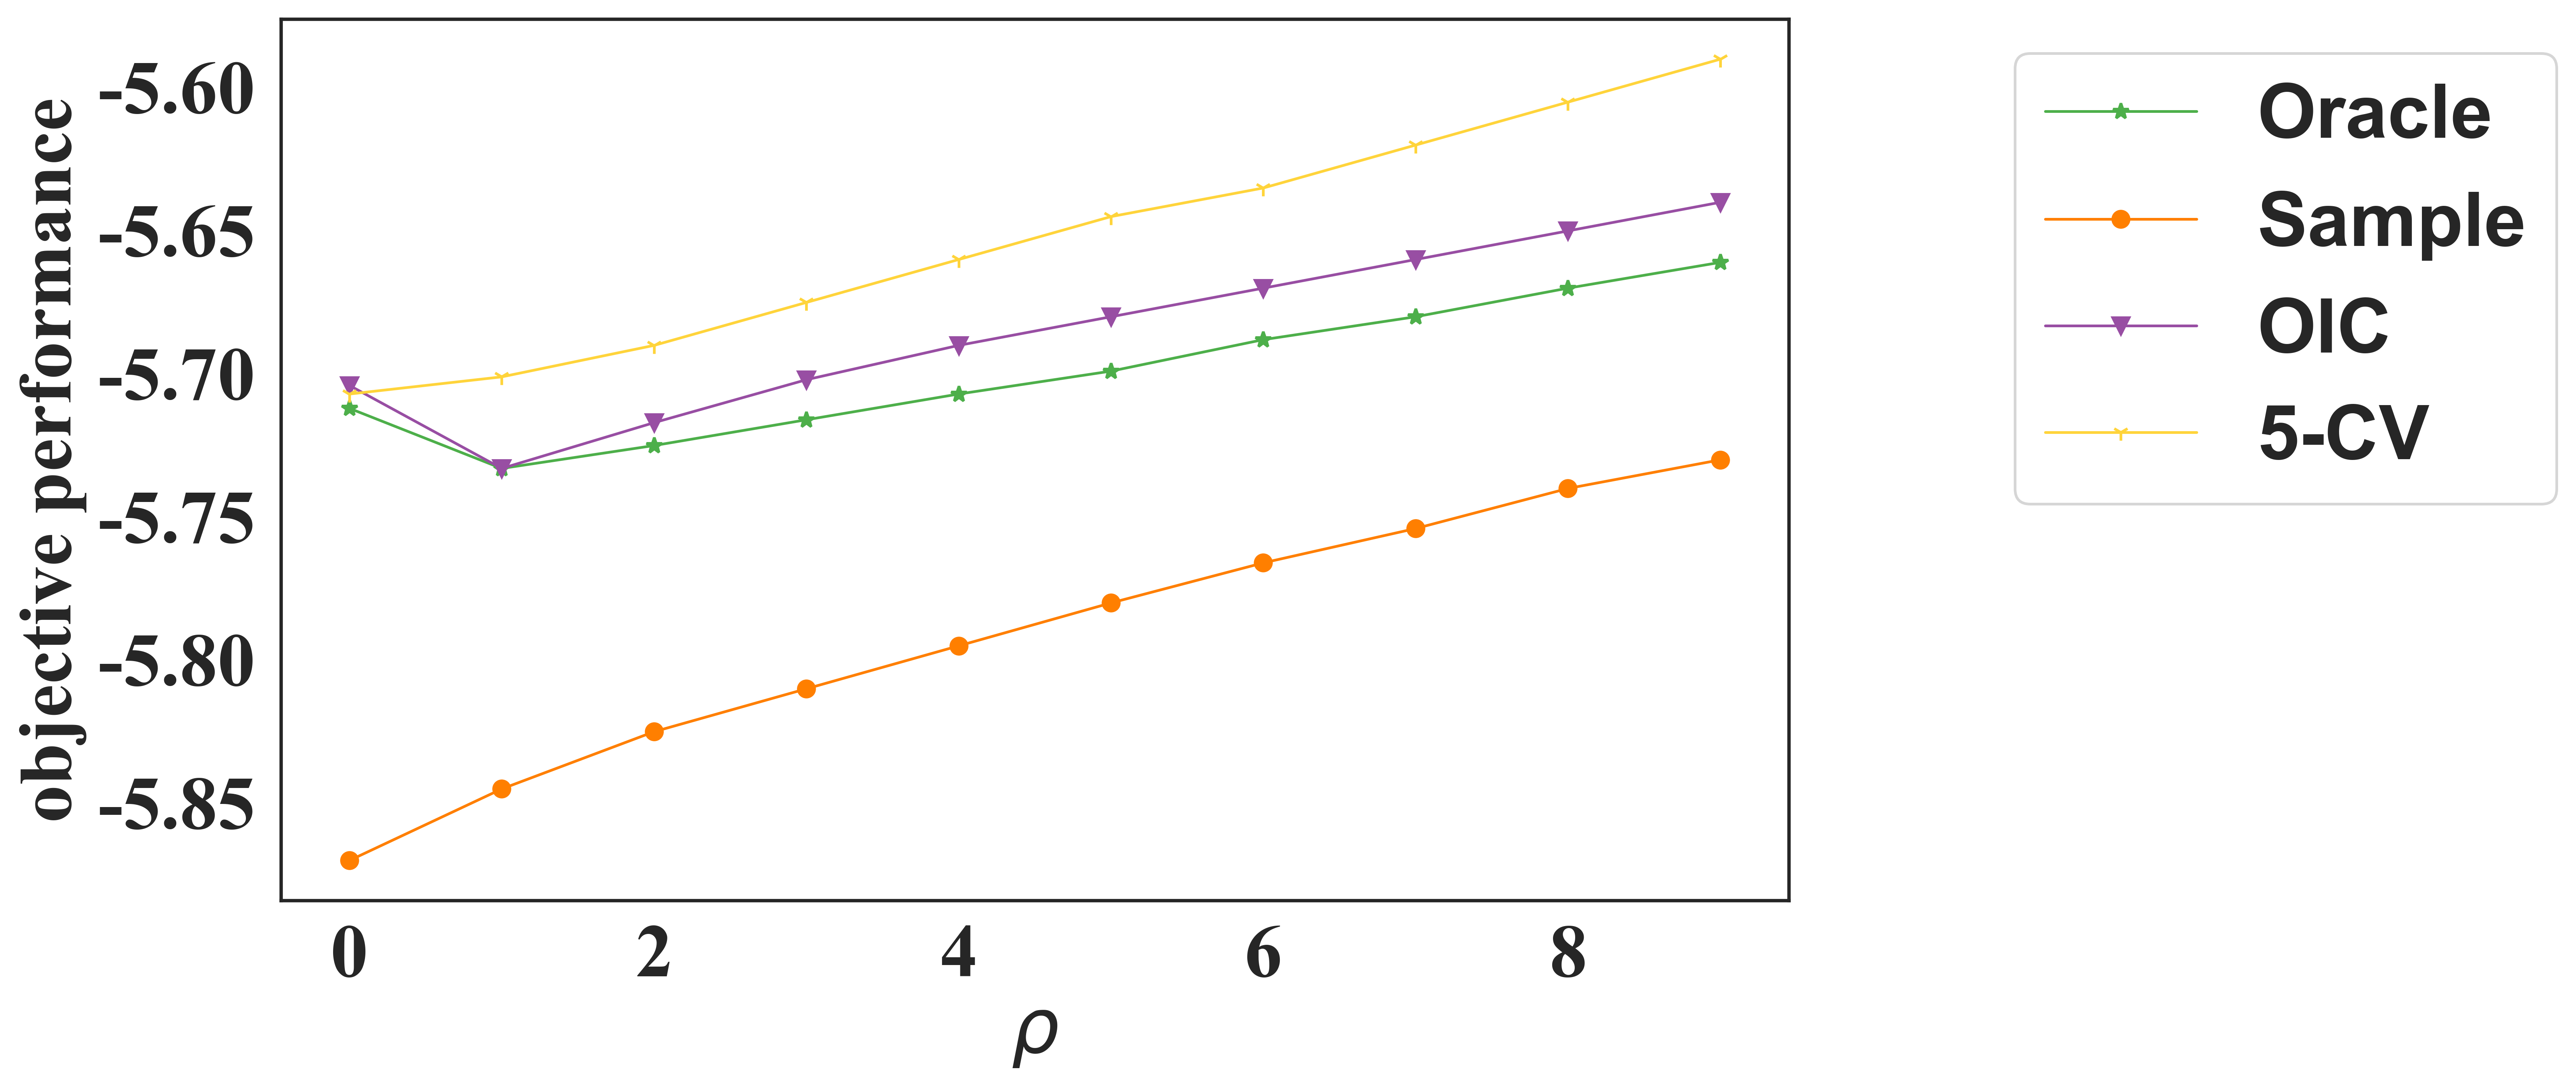

In [ ]:
marker_choice = ['*', 'o', 'v', '1', '2', '3']
colors=['#4daf4a', '#ff7f00', '#984ea3', '#FFD43B', '#a65628', '#f781bf', '#e41a1c', '#377eb8']

model_name = ['Oracle', 'Sample', 'OIC', '5-CV']
sns.set(style = 'white', font_scale = 1.75)
fig, ax = plt.subplots(figsize = (10, 6), dpi = 500)
plt.rc("axes.spines", top = False, right = False)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
csfont = {'fontname': "Times New Roman", 'size':28, 'weight':'bold'}


rho_list = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
final_perform_mean = np.zeros((4, 10))

final_perform_mean[0] = np.array([-5.712, -5.733, -5.725, -5.716, -5.707, -5.699, -5.688, -5.68, -5.67, -5.661])
final_perform_mean[1] = np.array([-5.87, -5.845, -5.825, -5.81, -5.795, -5.78, -5.766, -5.754, -5.74, -5.73])
final_perform_mean[2] = np.array([-5.704, -5.733, -5.717, -5.702, -5.69, -5.68, -5.67, -5.66, -5.65, -5.64])
final_perform_mean[3] = np.array([-5.707, -5.701, -5.69, -5.675, -5.66, -5.645, -5.635, -5.62, -5.605, -5.59])
for i in range(4):
    #model_index = [4* k + i for k in range(len(rho_list))]
    model_index = i
    plt.plot(rho_list, final_perform_mean[model_index], label = model_name[i], marker = marker_choice[i], color = colors[i], linewidth = 1) 
    #plt.errorbar(x = rho_list, y = final_perform_mean[model_index], yerr = final_perform_std[model_index] / math.sqrt(outer_num), color = colors[i], capsize = 2)

plt.legend(loc = 3, ncol = 1, prop = {'size':28, 'weight':'bold'}, bbox_to_anchor = (1.15, 0.45), borderaxespad = 0)
plt.xlabel(r'$\rho$', **csfont)
ax.set_xticks([0, 2, 4, 6,8])
ax.set_xticklabels(['0', '2', '4', '6', '8'], **csfont)

ax.set_yticks([-5.85, -5.80, -5.75, -5.70, -5.65, -5.60])
ax.set_yticklabels(['-5.85', '-5.80', '-5.75', '-5.70', '-5.65', '-5.60'], **csfont)
#ax.set_yticks([-5.8, -5.7, -5.6])
plt.ylabel('objective performance', **csfont)